# Laboratorul 6. Atenția: de la calculul de mână la un model real

*(Documentul-sursă este intitulat „Laboratorul 5. Transformers”; în cadrul cursului este Laboratorul 6.)*

**Conținut**
1. Pregătire: instalare, verificarea versiunilor, încărcarea modelelor (o singură dată)
2. Partea 1 — Atenția în NumPy (sarcinile 1.1–1.4) — *obligatorie*
3. Partea 2 — Tokenizarea (sarcinile 2.1–2.3) — *obligatorie*
4. Partea 3 — Generarea textului cu GPT-2 (sarcinile 3.1–3.2) — *obligatorie*; 3.3 RoGPT2 — *opțională*
5. Partea 4 — Embeddings contextuale și vizualizarea atenției — *bonus*
6. Răspunsurile la întrebările din secțiunea 7 (generate din valorile obținute la rulare)
7. Concluzii și listă de verificare

**Cum rulați în PyCharm**
- Deschideți fișierul `.ipynb` în PyCharm (Professional sau versiunea cu suport Jupyter).
- În colțul din dreapta-sus al notebook-ului alegeți interpretorul/kernel-ul proiectului (de ex. un *virtualenv* cu Python 3.10–3.13).
- Rulați celulele **în ordine, de sus în jos** (*Run All* sau Shift+Enter pe fiecare celulă).
- Dacă celula de instalare a instalat pachete noi, reporniți kernel-ul (*Restart Kernel*) și rulați din nou de la început.
- Totul rulează pe **CPU**; nu este nevoie de GPU NVIDIA. Prima rulare descarcă modelele (câteva sute de MB în total) în cache-ul Hugging Face; rulările următoare le iau din cache.

## 1. Pregătire

### 1.1 Instalarea dependențelor
Celula instalează PyTorch în varianta **CPU** (index-ul oficial PyTorch) și restul bibliotecilor. Dacă pachetele sunt deja instalate, `pip` doar confirmă și trece mai departe. După o instalare nouă, reporniți kernel-ul.

In [1]:
import sys, subprocess

INSTALEAZA = False   # puneți False după prima rulare reușită, ca să nu mai apelați pip

def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])

if INSTALEAZA:
    try:
        import torch  # noqa: F401  -- dacă există deja, nu îl reinstalăm
    except ImportError:
        pip_install("torch", "--index-url", "https://download.pytorch.org/whl/cpu")
    pip_install("numpy", "pandas", "matplotlib", "transformers", "bertviz", "ipywidgets")
    print("Instalare verificată. Dacă s-au instalat pachete noi: Restart Kernel și rulați din nou.")

### 1.2 Importuri, verificarea versiunilor și seed-uri

In [1]:
import os, platform, re, unicodedata, warnings
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")   # avertisment inofensiv pe Windows

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as Fn
import transformers
from transformers import AutoTokenizer, AutoModel, AutoModelForCausalLM
import matplotlib
import matplotlib.pyplot as plt

transformers.logging.set_verbosity_error()          # ascundem mesajele informative lungi
pd.set_option("display.max_colwidth", None)

print("Python      :", platform.python_version())
print("NumPy       :", np.__version__)
print("pandas      :", pd.__version__)
print("PyTorch     :", torch.__version__, "| CUDA disponibil:", torch.cuda.is_available())
print("transformers:", transformers.__version__)
print("matplotlib  :", matplotlib.__version__)
try:
    import bertviz
    print("bertviz     :", getattr(bertviz, "__version__", "instalat"))
except ImportError:
    print("bertviz     : NEINSTALAT (necesar doar pentru bonusul 4.2)")

DEVICE = torch.device("cpu")      # laboratorul rulează intenționat pe CPU
torch.manual_seed(42)
np.random.seed(42)

Python      : 3.12.16
NumPy       : 2.5.4
pandas      : 3.0.6
PyTorch     : 2.15.0+cpu | CUDA disponibil: False
transformers: 5.21.0
matplotlib  : 3.11.2
bertviz     : instalat


### 1.3 Încărcarea tokenizatoarelor și a modelelor (o singură dată)
Obiectele încărcate aici sunt **reutilizate** în tot notebook-ul:
- `tokenizere` — cele trei tokenizatoare (GPT-2, BERT multilingv, BERT românesc);
- `model` — GPT-2 pentru generare;
- `bert` — BERT-ul românesc cu `output_hidden_states=True` și atenție `eager` (doar pentru bonus; dacă încărcarea eșuează, părțile obligatorii continuă).

In [2]:
nume_modele = {
    "GPT-2": "gpt2",
    "BERT multilingv": "bert-base-multilingual-cased",
    "BERT românesc": "dumitrescustefan/bert-base-romanian-cased-v1",
}
tokenizere = {nume: AutoTokenizer.from_pretrained(m) for nume, m in nume_modele.items()}

tok = tokenizere["GPT-2"]
model = AutoModelForCausalLM.from_pretrained("gpt2").to(DEVICE)
model.eval()

# BERT românesc pentru bonus (Partea 4). Același obiect servește și pentru vizualizarea
# atenției: cerem atențiile la apel (output_attentions=True), deci nu încărcăm modelul de două ori.
nume_ro = nume_modele["BERT românesc"]
tok_bert = tokenizere["BERT românesc"]
try:
    bert = AutoModel.from_pretrained(nume_ro, output_hidden_states=True,
                                     attn_implementation="eager").to(DEVICE)
    bert.eval()
    BERT_OK = True
except Exception as e:
    bert, BERT_OK = None, False
    print("ATENȚIE: BERT românesc nu a putut fi încărcat; bonusul va fi sărit.", repr(e))

print("Gata: modelele sunt încărcate.")
print("Vocabular GPT-2:", len(tok), "| BERT românesc încărcat:", BERT_OK)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Gata: modelele sunt încărcate.
Vocabular GPT-2: 50257 | BERT românesc încărcat: True


## 2. Partea 1 — Atenția în NumPy

### Sarcina 1.1. Softmax stabil numeric
Scădem maximul pe fiecare rând înainte de `exp`, apoi împărțim la suma pe rând. Cu `axis=-1, keepdims=True` funcția merge și pentru vectori, și pentru matrice (rând cu rând).

In [3]:
np.set_printoptions(precision=3, suppress=True)

def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))   # scădem maximul de pe fiecare rând
    return e / e.sum(axis=-1, keepdims=True)         # împărțim la suma de pe fiecare rând

p_test = softmax(np.array([1.2, 2.8, 0.7]))
print(p_test)
assert np.allclose(p_test, [0.152, 0.755, 0.092], atol=1e-3), "Softmax nu corespunde verificării!"
print("✔ Verificare trecută: [0.152 0.755 0.092]")

[0.152 0.755 0.092]
✔ Verificare trecută: [0.152 0.755 0.092]


Softmax „naiv” (fără scăderea maximului) vs. varianta stabilă pentru scorurile `[1000, 1001]`. Capturăm și avertismentele NumPy, ca să se vadă ce se întâmplă.

In [4]:
s = np.array([1000.0, 1001.0])
with warnings.catch_warnings(record=True) as avertismente:
    warnings.simplefilter("always")
    exp_naiv = np.exp(s)
    p_naiv = exp_naiv / exp_naiv.sum()              # varianta naivă
p_stabil = softmax(s)                                # varianta noastră

print("np.exp(s)        :", exp_naiv)
print("softmax naiv     :", p_naiv)
print("softmax stabil   :", p_stabil)
print("Avertismente NumPy:", [str(w.message) for w in avertismente])
print("float64 maxim    :", np.finfo(np.float64).max, "| ln(max) ≈", round(np.log(np.finfo(np.float64).max), 2))

np.exp(s)        : [inf inf]
softmax naiv     : [nan nan]
softmax stabil   : [0.269 0.731]
Avertismente NumPy: ['overflow encountered in exp', 'invalid value encountered in divide']
float64 maxim    : 1.7976931348623157e+308 | ln(max) ≈ 709.78


**Explicație.** `exp(1000)` depășește cel mai mare număr reprezentabil în `float64` (≈ 1,8·10³⁰⁸, adică `exp(709,78)`), deci devine `inf`. Raportul `inf / inf` este nedefinit și dă `nan`. Varianta stabilă calculează `exp([-1, 0])`, valori perfect reprezentabile. Valorile exacte sunt afișate mai sus și sunt reluate automat în răspunsul la întrebarea 1.

### Sarcina 1.2. Funcția de atenție, verificată pe exemplul din curs
$$\text{Attention}(Q,K,V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

In [5]:
def attention(Q, K, V, mask=None):
    d_k = K.shape[-1]
    scores = Q @ K.T / np.sqrt(d_k)                  # Q·Kᵀ / √d_k
    if mask is not None:
        scores = np.where(mask, scores, -np.inf)     # pozițiile interzise primesc -inf -> pondere 0
    weights = softmax(scores)
    return weights @ V, weights

# Datele din exemplul rezolvat (Lecția 5, după pasul 7)
q = np.array([[2, 1, 0, 1]])              # q pentru „aprobat”
K = np.array([[0.5, 1.0, 0.3, 0.4],       # k pentru „Banca”
              [2.0, 1.0, 0.5, 0.6],       # k pentru „creditul”
              [0.2, 0.6, 0.9, 0.4]])      # k pentru „clientului”
V = np.array([[1.0, 0.0],
              [0.0, 1.0],
              [0.5, 0.5]])

z, w = attention(q, K, V)
print("ponderi:", w)
print("z:", z)
assert np.allclose(w, [[0.152, 0.755, 0.092]], atol=1e-3)
assert np.allclose(z, [[0.199, 0.801]], atol=1e-3)
print("✔ Verificare trecută: ponderi [0.152 0.755 0.092], z = [0.199 0.801]")
print("  (în lecție: (0,195; 0,805), pentru că acolo s-au folosit ponderile rotunjite 0,15; 0,76; 0,09)")

ponderi: [[0.152 0.755 0.092]]
z: [[0.199 0.801]]
✔ Verificare trecută: ponderi [0.152 0.755 0.092], z = [0.199 0.801]
  (în lecție: (0,195; 0,805), pentru că acolo s-au folosit ponderile rotunjite 0,15; 0,76; 0,09)


### Sarcina 1.3. Toți tokenii deodată, cu mască cauzală
4 tokeni × 8 componente, trei matrice $W$ aleatoare, seed fix `42`. Pasul 4 din lecție: $Q = XW_Q$, $K = XW_K$, $V = XW_V$.

In [6]:
rng = np.random.default_rng(42)
X = rng.normal(size=(4, 8))                              # 4 tokeni × 8 componente
W_Q, W_K, W_V = (rng.normal(size=(8, 4)) for _ in range(3))
Q, K, V = X @ W_Q, X @ W_K, X @ W_V                      # pasul 4 din lecție

mask = np.tril(np.ones((4, 4), dtype=bool))              # True = tokenul poate fi văzut
print(mask)
Z, W = attention(Q, K, V, mask)
print(W)
print("Suma pe rânduri:", W.sum(axis=1))

assert np.allclose(W.sum(axis=1), 1.0)
assert np.all(W[np.triu_indices(4, k=1)] == 0), "Există ponderi nenule deasupra diagonalei!"
assert np.allclose(W[0], [1, 0, 0, 0])
assert np.allclose(W[1], [0.648, 0.352, 0, 0], atol=1e-3)
print("✔ Verificări trecute: sume = 1, zerouri deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]")

[[ True False False False]
 [ True  True False False]
 [ True  True  True False]
 [ True  True  True  True]]
[[1.    0.    0.    0.   ]
 [0.648 0.352 0.    0.   ]
 [0.491 0.145 0.363 0.   ]
 [0.285 0.341 0.281 0.093]]
Suma pe rânduri: [1. 1. 1. 1.]
✔ Verificări trecute: sume = 1, zerouri deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]


### Sarcina 1.4. Multi-head attention cu două capete
Fiecare cap are propriile $(W_Q, W_K, W_V)$ de dimensiune 8×4 și dă câte 4 componente pe token; după concatenare (4+4 = 8) înmulțim cu $W_O$ (8×8).

*Notă:* `heads` și `W_O` sunt generate cu **același** `rng`, în continuarea secvenței de la sarcina 1.3, exact ca în document.

In [7]:
def multi_head(X, heads, W_O):
    # heads = listă de tupluri (W_Q, W_K, W_V), câte unul pe cap
    outs = [attention(X @ Wq, X @ Wk, X @ Wv)[0] for Wq, Wk, Wv in heads]
    concat = np.concatenate(outs, axis=-1)
    return concat @ W_O                                  # matricea care combină capetele

heads = [tuple(rng.normal(size=(8, 4)) for _ in range(3)) for _ in range(2)]
W_O = rng.normal(size=(8, 8))
iesire_mh = multi_head(X, heads, W_O)
print(iesire_mh.shape)
assert iesire_mh.shape == (4, 8)
print("✔ Verificare trecută: dimensiunea (4, 8)")

(4, 8)
✔ Verificare trecută: dimensiunea (4, 8)


## 3. Partea 2 — Tokenizarea
Comparăm GPT-2 (antrenat mai ales pe engleză), BERT multilingv (104 limbi) și BERT românesc. Tokenizatoarele au fost deja încărcate în secțiunea 1.3 (`tokenizere`).

*GPT-2 lucrează la nivel de octeți, de aceea literele românești (ă, î, ș, ț) apar ca simboluri ciudate (de ex. `Ä`). `Ġ` marchează un spațiu înaintea tokenului. La BERT, `##` marchează continuarea unui cuvânt.*

In [8]:
fraze = ["Banca a aprobat creditul clientului.",
         "Împrumuturile restructurate au dobânzi variabile."]

nr_tokeni = {}
for nume, tk in tokenizere.items():
    for j, f in enumerate(fraze, start=1):
        t = tk.tokenize(f)
        nr_tokeni[(nume, j)] = len(t)
        print(f"{nume:16} {len(t):3} {t}")

GPT-2             12 ['B', 'anca', 'Ġa', 'Ġa', 'pro', 'bat', 'Ġcredit', 'ul', 'Ġclient', 'ul', 'ui', '.']
GPT-2             20 ['Ã', 'İ', 'm', 'pr', 'um', 'ut', 'ur', 'ile', 'Ġrestruct', 'urate', 'Ġau', 'Ġdo', 'b', 'Ã¢', 'n', 'zi', 'Ġvari', 'ab', 'ile', '.']
BERT multilingv   10 ['Banca', 'a', 'ap', '##ro', '##bat', 'credit', '##ul', 'client', '##ului', '.']
BERT multilingv   15 ['Î', '##mp', '##rumu', '##turi', '##le', 'rest', '##ru', '##ctura', '##te', 'au', 'dob', '##ân', '##zi', 'variabile', '.']
BERT românesc      6 ['Banca', 'a', 'aprobat', 'creditul', 'clientului', '.']
BERT românesc      8 ['Împrum', '##uturile', 'restruct', '##urate', 'au', 'dobânzi', 'variabile', '.']


### Sarcina 2.1. Tabelul cu numărul de tokeni (completat automat)

In [9]:
tabel_tokeni = pd.DataFrame(
    {"Fraza 1": [nr_tokeni[(n, 1)] for n in tokenizere],
     "Fraza 2": [nr_tokeni[(n, 2)] for n in tokenizere]},
    index=pd.Index(list(tokenizere), name="Model"))
# câte cuvinte (separate prin spațiu) are fiecare frază, ca reper
tabel_tokeni.loc["(cuvinte, ca reper)"] = [len(f.split()) for f in fraze]
tabel_tokeni

,Fraza 1,Fraza 2
Model,,
GPT-2,12,20
BERT multilingv,10,15
BERT românesc,6,8
"(cuvinte, ca reper)",5,5


### Sarcina 2.2. Cât „costă” limba română?

In [10]:
gpt2 = tokenizere["GPT-2"]
fraza_ro = "Banca a aprobat creditul clientului."
fraza_en = "The bank approved the client's loan."
n_ro = len(gpt2.tokenize(fraza_ro))
n_en = len(gpt2.tokenize(fraza_en))
raport_ro_en = round(n_ro / n_en, 2)
print(n_ro, n_en, raport_ro_en)
print("RO:", gpt2.tokenize(fraza_ro))
print("EN:", gpt2.tokenize(fraza_en))

# Cost ipotetic: 1 USD / 1 milion de tokeni; 1 milion de fraze
PRET_USD_PER_TOKEN = 1 / 1_000_000
NR_FRAZE = 1_000_000
cost_ro = n_ro * NR_FRAZE * PRET_USD_PER_TOKEN
cost_en = n_en * NR_FRAZE * PRET_USD_PER_TOKEN
print(f"Cost pentru 1 milion de fraze: RO = {cost_ro:.2f} USD, EN = {cost_en:.2f} USD, "
      f"diferență = {cost_ro - cost_en:.2f} USD")

12 8 1.5
RO: ['B', 'anca', 'Ġa', 'Ġa', 'pro', 'bat', 'Ġcredit', 'ul', 'Ġclient', 'ul', 'ui', '.']
EN: ['The', 'Ġbank', 'Ġapproved', 'Ġthe', 'Ġclient', "'s", 'Ġloan', '.']
Cost pentru 1 milion de fraze: RO = 12.00 USD, EN = 8.00 USD, diferență = 4.00 USD


### Sarcina 2.3. Diacriticele cu virgulă și cu sedilă (BERT românesc)
`ș` (U+0219) și `ț` (U+021B) sunt formele corecte cu virgulă; `ş` (U+015F) și `ţ` (U+0163) sunt formele vechi cu sedilă. Pentru calculator sunt caractere diferite.

In [11]:
ro = tokenizere["BERT românesc"]
text_virgula = "știință și țară"     # ș, ț cu virgulă
text_sedila  = "ştiinţă şi ţară"     # ş, ţ cu sedilă

tok_virgula = ro.tokenize(text_virgula)
tok_sedila  = ro.tokenize(text_sedila)
print("virgulă:", len(tok_virgula), tok_virgula)
print("sedilă :", len(tok_sedila), tok_sedila)
print("Coduri Unicode:", {c: f"U+{ord(c):04X}" for c in "șşțţ"})
print("Tokenizare identică?", tok_virgula == tok_sedila)
print("Apare [UNK]? virgulă:", ro.unk_token in tok_virgula, "| sedilă:", ro.unk_token in tok_sedila)

virgulă: 3 ['știință', 'și', 'țară']
sedilă : 3 ['[UNK]', '[UNK]', '[UNK]']
Coduri Unicode: {'ș': 'U+0219', 'ş': 'U+015F', 'ț': 'U+021B', 'ţ': 'U+0163'}
Tokenizare identică? False
Apare [UNK]? virgulă: False | sedilă: True


**Preprocesare propusă:** normalizare Unicode (NFC) + înlocuirea formelor cu sedilă cu cele cu virgulă (`ş→ș`, `ţ→ț`, `Ş→Ș`, `Ţ→Ț`). Verificăm efectul pe tokenizare:

In [12]:
SEDILA_LA_VIRGULA = str.maketrans({"ş": "ș", "ţ": "ț", "Ş": "Ș", "Ţ": "Ț"})

def normalizeaza_ro(text):
    return unicodedata.normalize("NFC", text).translate(SEDILA_LA_VIRGULA)

tok_sedila_normalizat = ro.tokenize(normalizeaza_ro(text_sedila))
print("sedilă după normalizare:", tok_sedila_normalizat)
print("Identic cu varianta cu virgulă?", tok_sedila_normalizat == tok_virgula)

sedilă după normalizare: ['știință', 'și', 'țară']
Identic cu varianta cu virgulă? True


**Observații (Partea 2).** Interpretarea se bazează pe tabelul și listele de mai sus, nu pe valori presupuse dinainte; formularea cu numerele concrete este generată automat în secțiunea 6 (întrebările 3 și 4). De urmărit:
- care tokenizator împarte frazele românești în cele mai puține bucăți și dacă un cuvânt românesc rămâne întreg sau este fragmentat;
- de câte ori sunt fragmentate literele cu diacritice la GPT-2 (fiecare literă cu diacritic are 2 octeți în UTF-8);
- dacă forma cu sedilă produce mai mulți tokeni sau `[UNK]` la BERT românesc.

## 4. Partea 3 — Generarea textului cu GPT-2
GPT-2 este un model „doar decoder”; lucrăm în engleză, pentru că a fost antrenat pe texte în engleză. Modelul `model` și tokenizatorul `tok` au fost încărcate în secțiunea 1.3.

### Sarcina 3.1. Probabilitățile pentru următorul token
Funcția `top10` este cea din document; în plus **returnează** valorile, ca să le putem folosi în răspunsuri.

In [13]:
def top10(model, tok, text):
    ids = tok(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        logits = model(ids).logits[0, -1]            # scorurile pentru ULTIMA poziție
    print("Dimensiunea vectorului logits:", logits.shape)
    probs = torch.softmax(logits, dim=-1)
    print("Suma probabilităților:", probs.sum().item())
    top = torch.topk(probs, 10)
    rezultat = []
    for p, i in zip(top.values, top.indices):
        print(f"{tok.decode(int(i))!r:16} {p.item():.3f}")
        rezultat.append((tok.decode(int(i)), p.item()))
    return {"dim_logits": tuple(logits.shape), "suma": probs.sum().item(),
            "top": rezultat, "logits": logits}

rez_31 = top10(model, tok, "The bank approved the")

Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.000011920928955
' loan'          0.066
' deal'          0.066
' sale'          0.037
' transaction'   0.033
' plan'          0.025
' purchase'      0.024
' new'           0.019
' $'             0.019
' move'          0.016
' settlement'    0.012


In [14]:
print("Primii trei tokeni propuși:")
for k, (t, p) in enumerate(rez_31["top"][:3], start=1):
    print(f"  {k}. {t!r}  p = {p:.3f}  ({p:.1%})")
print("Dimensiunea logits:", rez_31["dim_logits"], "| mărimea vocabularului GPT-2:", len(tok),
      "| config.vocab_size:", model.config.vocab_size)

Primii trei tokeni propuși:
  1. ' loan'  p = 0.066  (6.6%)
  2. ' deal'  p = 0.066  (6.6%)
  3. ' sale'  p = 0.037  (3.7%)
Dimensiunea logits: (50257,) | mărimea vocabularului GPT-2: 50257 | config.vocab_size: 50257


### Sarcina 3.2. Bucla de generare, scrisă de mână
Fără `model.generate()`: **prezice → alege → adaugă → repetă**. Temperatura împarte scorurile **înainte** de Softmax.

In [15]:
def genereaza(model, tok, text, n_tokeni=25, temperatura=1.0, greedy=False):
    ids = tok(text, return_tensors="pt").input_ids.to(DEVICE)
    for _ in range(n_tokeni):
        with torch.no_grad():
            logits = model(ids).logits[0, -1]
        if greedy:
            urm = torch.argmax(logits)                         # tokenul cu scor maxim
        else:
            probs = torch.softmax(logits / temperatura, dim=-1)  # temperatura
            urm = torch.multinomial(probs, 1)[0]                 # extragere aleatoare
        ids = torch.cat([ids, urm.view(1, 1)], dim=1)            # adăugăm tokenul
    return tok.decode(ids[0])

Rulăm varianta greedy (de două ori, ca să verificăm că dă același text) și câte două încercări pentru T = 0,2 / 0,7 / 1,5, cu **seed-uri explicite** pentru fiecare încercare.

*Reproductibilitate:* cu același seed, aceeași versiune de PyTorch/transformers și același CPU, textele se repetă la rulări succesive. Între sisteme de operare, procesoare sau versiuni diferite ale bibliotecilor, eșantionarea poate da alte texte (mici diferențe numerice în logits schimbă extragerea). Varianta greedy nu depinde de seed.

In [16]:
text_prompt = "The bank approved the"
N_TOKENI = 25
TEMPERATURI = [0.2, 0.7, 1.5]

def seed_pentru(T, incercare):
    return 1000 + int(T * 10) * 10 + incercare      # ex.: T=0.7, încercarea 1 -> 1071

rezultate_gen = []
greedy_1 = genereaza(model, tok, text_prompt, n_tokeni=N_TOKENI, greedy=True)
greedy_2 = genereaza(model, tok, text_prompt, n_tokeni=N_TOKENI, greedy=True)
greedy_identic = greedy_1 == greedy_2
print("GREEDY:", greedy_1)
print("Greedy rulat de două ori dă același text?", greedy_identic)
rezultate_gen.append({"Setare": "Greedy", "Încercare": 1, "Seed": "-", "Text": greedy_1})

for T in TEMPERATURI:
    for incercare in range(2):
        seed = seed_pentru(T, incercare)
        torch.manual_seed(seed)
        t = genereaza(model, tok, text_prompt, n_tokeni=N_TOKENI, temperatura=T)
        print(f"T = {T} (seed {seed}):", t)
        rezultate_gen.append({"Setare": f"T = {T}", "Încercare": incercare + 1, "Seed": seed, "Text": t})

GREEDY: The bank approved the loan in May, but the bank has not yet approved the loan.

The bank said it will not be able to
Greedy rulat de două ori dă același text? True
T = 0.2 (seed 1020): The bank approved the deal on Friday, but the deal has yet to be signed.

The bank said it would not be able to pay
T = 0.2 (seed 1021): The bank approved the deal on Tuesday, but it has yet to announce its financial results.

The bank's chief executive, Mark Carney,
T = 0.7 (seed 1070): The bank approved the agreement on Tuesday, calling it a "fairly fair and effective agreement" that "will reduce the risk that the Government may
T = 0.7 (seed 1071): The bank approved the purchase at a market rate of 2.5 percent. The bank also agreed to pay $3.7 billion for the capital
T = 1.5 (seed 1150): The bank approved the project as another thrust in its bid to restave shortage came 2016. Starbucks seems willingHider aquil nonprofits retailers specifically focus
T = 1.5 (seed 1151): The bank approved the n

Indicatori simpli, calculați automat, care ajută la completarea observațiilor (nu le înlocuiesc):
- **tokeni unici %** — proporția tokenilor distincți din partea generată (mic ⇒ repetitiv);
- **max. repetări 3-gram** — de câte ori apare cea mai frecventă secvență de 3 tokeni (mare ⇒ bucle).

Calculăm și **entropia** distribuției următorului token pentru prompt la fiecare temperatură: arată direct cum se „ascute” sau se „aplatizează” Softmax-ul.

In [17]:
from collections import Counter

n_prompt = len(tok(text_prompt).input_ids)

def indicatori(text):
    gen = tok(text).input_ids[n_prompt:]                 # doar partea generată
    trigr = Counter(tuple(gen[i:i + 3]) for i in range(len(gen) - 2))
    return round(100 * len(set(gen)) / max(len(gen), 1), 1), (max(trigr.values()) if trigr else 0)

for r in rezultate_gen:
    r["Tokeni unici %"], r["Max. repetări 3-gram"] = indicatori(r["Text"])
tabel_generare = pd.DataFrame(rezultate_gen)
display(tabel_generare)

# Efectul temperaturii asupra distribuției Softmax pentru promptul "The bank approved the"
logits_prompt = rez_31["logits"]
efect_T = []
for T in [0.2, 0.7, 1.0, 1.5]:
    p = torch.softmax(logits_prompt / T, dim=-1)
    entropie = -(p * torch.log(p.clamp_min(1e-12))).sum().item()
    efect_T.append({"T": T, "p(top-1)": round(p.max().item(), 4),
                    "masa top-10": round(torch.topk(p, 10).values.sum().item(), 4),
                    "entropie (nats)": round(entropie, 3)})
tabel_temperatura = pd.DataFrame(efect_T)
tabel_temperatura

,Setare,Încercare,Seed,Text,Tokeni unici %,Max. repetări 3-gram
0,Greedy,1,-,"The bank approved the loan in May, but the bank has not yet approved the loan.\n\nThe bank said it will not be able to",80.0,1
1,T = 0.2,1,1020,"The bank approved the deal on Friday, but the deal has yet to be signed.\n\nThe bank said it would not be able to pay",84.0,1
2,T = 0.2,2,1021,"The bank approved the deal on Tuesday, but it has yet to announce its financial results.\n\nThe bank's chief executive, Mark Carney,",88.0,1
3,T = 0.7,1,1070,"The bank approved the agreement on Tuesday, calling it a ""fairly fair and effective agreement"" that ""will reduce the risk that the Government may",84.0,1
4,T = 0.7,2,1071,The bank approved the purchase at a market rate of 2.5 percent. The bank also agreed to pay $3.7 billion for the capital,92.0,1
5,T = 1.5,1,1150,The bank approved the project as another thrust in its bid to restave shortage came 2016. Starbucks seems willingHider aquil nonprofits retailers specifically focus,100.0,1
6,T = 1.5,2,1151,"The bank approved the new bank logo, historical USPS another -- 3W59. $63Us came with John to Ray joint referencing -BD",100.0,1


,T,p(top-1),masa top-10,entropie (nats)
0,0.2,0.4818,0.9997,0.924
1,0.7,0.1753,0.6722,3.741
2,1.0,0.0661,0.3164,6.215
3,1.5,0.0128,0.0756,8.674


**Tabelul de observații (de completat după rulare, pe baza textelor și indicatorilor de mai sus):**

| Setare | Ce ați observat (repetitiv / coerent / variat / incoerent) |
|---|---|
| Greedy | *(completați)* |
| T = 0,2 | *(completați)* |
| T = 0,7 | *(completați)* |
| T = 1,5 | *(completați)* |

*Tiparul tipic la GPT-2 (de confirmat cu textele voastre, nu presupus):* greedy și T mic tind să intre în bucle repetitive; T ≈ 0,7 dă de obicei text variat și relativ coerent; T = 1,5 dă text foarte variat, adesea incoerent.

### Sarcina 3.3. (opțional) RoGPT2 pentru limba română
Dacă modelul `readerbench/RoGPT2-base` nu poate fi descărcat sau încărcat, celula afișează un mesaj și notebook-ul continuă.

In [18]:
ROGPT2_OK = False
try:
    tok_ro_gpt = AutoTokenizer.from_pretrained("readerbench/RoGPT2-base")
    model_ro_gpt = AutoModelForCausalLM.from_pretrained("readerbench/RoGPT2-base").to(DEVICE)
    model_ro_gpt.eval()
    ROGPT2_OK = True
except Exception as e:
    print("RoGPT2 nu a putut fi încărcat; sarcina opțională 3.3 este sărită.\nMotiv:", repr(e))

if ROGPT2_OK:
    rez_33 = top10(model_ro_gpt, tok_ro_gpt, "Banca a aprobat")
    torch.manual_seed(2021)
    print("\nT = 0.7 (seed 2021):", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", temperatura=0.7))
    print("GREEDY             :", genereaza(model_ro_gpt, tok_ro_gpt, "Banca a aprobat", greedy=True))

Loading weights:   0%|          | 0/149 [00:00<?, ?it/s]

Dimensiunea vectorului logits: torch.Size([50257])
Suma probabilităților: 1.0000123977661133
' în'            0.108
' un'            0.075
','              0.060
' o'             0.050
'-'              0.049
' finanțarea'    0.013
' planul'        0.013
' pentru'        0.013
' la'            0.012
' și'            0.010

T = 0.7 (seed 2021): Banca a aprobat cererea guvernului Regatului Unit de a permite guvernului britanic să plătească o parte din datoriile sale către Republica Irlanda, permițând astfel transferul de fonduri
GREEDY             : Banca a aprobat în octombrie 2018 un împrumut de 1,5 miliarde de euro de la Banca Europeană de Investiții (BEI) pentru finanțarea proiectelor


*RoGPT2-base este un model mic, publicat în 2021; româna generată va fi imperfectă. Ne interesează mecanismul, nu calitatea textului.*

## 5. Partea 4 (bonus) — Embeddings contextuale și vizualizarea atenției
BERT-ul românesc are 12 blocuri. `hidden_states[0]` = ieșirea pasului 3 (embedding + poziție), `hidden_states[12]` = ieșirea ultimului bloc.

### Sarcina 4.1. Vectorul lui „bancă” în patru propoziții

In [19]:
fraze_banca = ["Am deschis un cont la bancă.",
               "Am luat un credit de la bancă.",
               "M-am așezat pe o bancă în parc.",
               "Bătrânul stă pe bancă lângă fântână."]

def vector_cuvant(fraza, cuvant, strat):
    enc = tok_bert(fraza, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = bert(**enc)
    tokens = tok_bert.convert_ids_to_tokens(enc.input_ids[0])
    parti = tok_bert.tokenize(cuvant)                     # cuvântul poate avea mai mulți tokeni
    for i in range(len(tokens) - len(parti) + 1):
        if tokens[i:i + len(parti)] == parti:
            return out.hidden_states[strat][0, i:i + len(parti)].mean(dim=0)
    raise ValueError(f"Nu am găsit „{cuvant}” în: {fraza}")

sim_banca = {}
if BERT_OK:
    print("Tokenii lui „bancă”:", tok_bert.tokenize("bancă"))
    for strat in [0, 12]:
        vecs = torch.stack([vector_cuvant(f, "bancă", strat) for f in fraze_banca])
        sim = Fn.cosine_similarity(vecs.unsqueeze(1), vecs.unsqueeze(0), dim=-1)
        sim_banca[strat] = sim.numpy()
        print(f"Stratul {strat}:")
        print(sim.numpy().round(3))
else:
    print("BERT românesc nu este disponibil — sarcina 4.1 este sărită.")

Tokenii lui „bancă”: ['bancă']
Stratul 0:
[[1.    0.971 0.971 0.961]
 [0.971 1.    1.    0.954]
 [0.971 1.    1.    0.954]
 [0.961 0.954 0.954 1.   ]]
Stratul 12:
[[1.    0.953 0.659 0.594]
 [0.953 1.    0.625 0.56 ]
 [0.659 0.625 1.    0.832]
 [0.594 0.56  0.832 1.   ]]


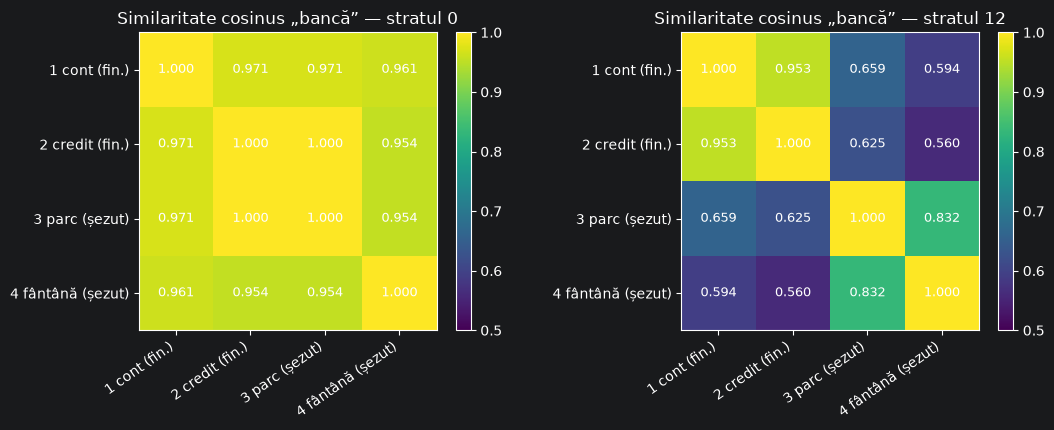

Stratul  0: sim(1,2) = 0.971 | sim(1,3) = 0.971 | media financiar–șezut = 0.972 | 1–2 mai apropiate decât 1–3? False
Stratul 12: sim(1,2) = 0.953 | sim(1,3) = 0.659 | media financiar–șezut = 0.609 | 1–2 mai apropiate decât 1–3? True


In [20]:
if BERT_OK:
    etichete = ["1 cont (fin.)", "2 credit (fin.)", "3 parc (șezut)", "4 fântână (șezut)"]
    fig, axe = plt.subplots(1, 2, figsize=(11, 4.4))
    for ax, strat in zip(axe, [0, 12]):
        m = sim_banca[strat]
        im = ax.imshow(m, cmap="viridis", vmin=min(m.min(), 0.5), vmax=1)
        ax.set_xticks(range(4), etichete, rotation=35, ha="right"); ax.set_yticks(range(4), etichete)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{m[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
        ax.set_title(f"Similaritate cosinus „bancă” — stratul {strat}")
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()

    for strat in [0, 12]:
        m = sim_banca[strat]
        fin = m[0, 1]
        sez = np.mean([m[0, 2], m[0, 3], m[1, 2], m[1, 3]])
        print(f"Stratul {strat:2}: sim(1,2) = {m[0, 1]:.3f} | sim(1,3) = {m[0, 2]:.3f} | "
              f"media financiar–șezut = {sez:.3f} | 1–2 mai apropiate decât 1–3? {m[0, 1] > m[0, 2]}")

### Sarcina 4.2. Vizualizarea atenției cu `bertviz`
`head_view` produce o interfață HTML + JavaScript. În PyCharm, ieșirile JavaScript din notebook nu sunt întotdeauna executate (depinde de versiune și de setările de *trusted notebook*), deci:
1. încercăm afișarea direct în notebook;
2. salvăm aceeași vizualizare în `atentie_bertviz.html`, care se deschide în orice browser (necesită internet, pentru că bertviz încarcă `require.js` și `d3` de pe CDN);
3. ca alternativă fără JavaScript, căutăm **automat** capul în care „aprobat” se uită cel mai mult la „creditul” și desenăm cu matplotlib matricea lui de atenție.

Folosim modelul `bert` deja încărcat (atenție `eager`) și cerem atențiile la apel cu `output_attentions=True`.

In [21]:
fraza_att = "Banca a aprobat creditul clientului."
att, tokens_att = None, None
if BERT_OK:
    enc_att = tok_bert(fraza_att, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        att = bert(**enc_att, output_attentions=True).attentions   # 12 tensori [1, capete, n, n]
    tokens_att = tok_bert.convert_ids_to_tokens(enc_att.input_ids[0])
    print("Tokeni:", tokens_att)
    print("Straturi:", len(att), "| formă per strat:", tuple(att[0].shape))

    try:
        from bertviz import head_view
        from IPython.display import display as ipy_display
        html_obj = head_view(att, tokens_att, html_action="return")
        with open("atentie_bertviz.html", "w", encoding="utf-8") as fh:
            fh.write(html_obj.data)
        print("Vizualizarea a fost salvată în:", os.path.abspath("atentie_bertviz.html"))
        ipy_display(html_obj)      # dacă în PyCharm nu apare nimic, deschideți fișierul HTML în browser
    except Exception as e:
        print("bertviz nu a putut afișa vizualizarea:", repr(e), "\nFolosiți alternativa matplotlib de mai jos.")
else:
    print("BERT românesc nu este disponibil — sarcina 4.2 este sărită.")

Tokeni: ['[CLS]', 'Banca', 'a', 'aprobat', 'creditul', 'clientului', '.', '[SEP]']
Straturi: 12 | formă per strat: (1, 12, 8, 8)
Vizualizarea a fost salvată în: C:\Users\marce\PycharmProjects\Lab5_AIGen\atentie_bertviz.html


„aprobat” → „creditul”: maxim în stratul 2 (index 1), capul 4 (index 3), pondere = 0.995
Top 5 (strat, cap, pondere) — numerotare de la 1, ca în bertviz:
  stratul  2, capul  4: 0.995
  stratul  3, capul 11: 0.947
  stratul  8, capul 12: 0.891
  stratul  5, capul  8: 0.560
  stratul 10, capul  8: 0.464


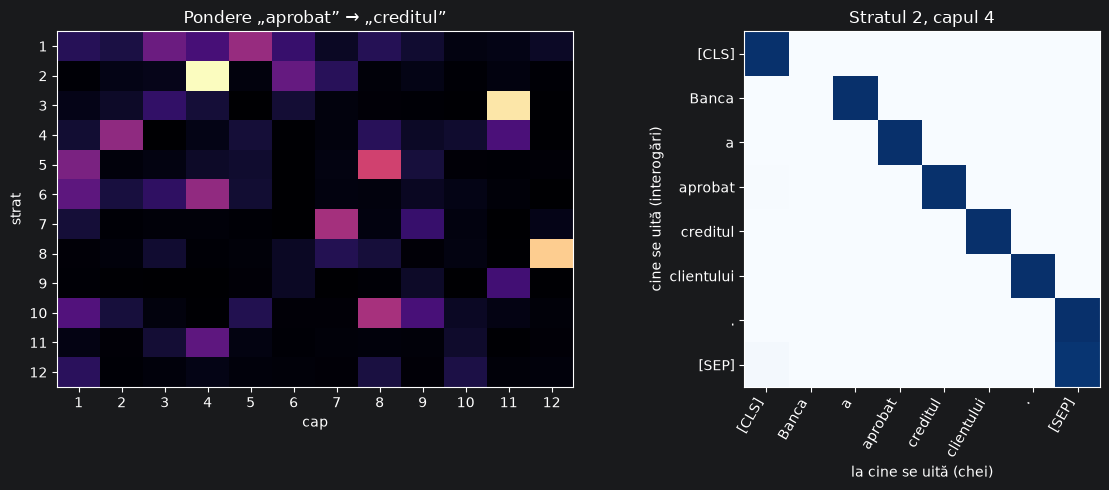

In [22]:
def pozitii_cuvant(tokens, cuvant):
    parti = tok_bert.tokenize(cuvant)
    for i in range(len(tokens) - len(parti) + 1):
        if tokens[i:i + len(parti)] == parti:
            return list(range(i, i + len(parti)))
    raise ValueError(f"Nu am găsit „{cuvant}” în {tokens}")

cap_aprobat_credit = None
if att is not None:
    poz_aprobat = pozitii_cuvant(tokens_att, "aprobat")
    poz_credit = pozitii_cuvant(tokens_att, "creditul")
    A = torch.stack([a[0] for a in att])                 # [straturi, capete, n, n]
    # atenția de la „aprobat” (medie pe sub-tokeni) către „creditul” (sumă pe sub-tokeni)
    scor = A[:, :, poz_aprobat][:, :, :, poz_credit].sum(-1).mean(-1)   # [straturi, capete]
    strat_max, cap_max = divmod(int(scor.argmax()), scor.shape[1])
    cap_aprobat_credit = (strat_max, cap_max, scor[strat_max, cap_max].item())
    print(f"„aprobat” → „creditul”: maxim în stratul {strat_max + 1} (index {strat_max}), "
          f"capul {cap_max + 1} (index {cap_max}), pondere = {scor[strat_max, cap_max]:.3f}")
    top5 = torch.topk(scor.flatten(), 5)
    print("Top 5 (strat, cap, pondere) — numerotare de la 1, ca în bertviz:")
    for v, idx in zip(top5.values, top5.indices):
        s_, c_ = divmod(int(idx), scor.shape[1])
        print(f"  stratul {s_ + 1:2}, capul {c_ + 1:2}: {v:.3f}")

    fig, axe = plt.subplots(1, 2, figsize=(12, 5))
    axe[0].imshow(scor.numpy(), cmap="magma", aspect="auto")
    axe[0].set_title("Pondere „aprobat” → „creditul”"); axe[0].set_xlabel("cap"); axe[0].set_ylabel("strat")
    axe[0].set_xticks(range(scor.shape[1]), range(1, scor.shape[1] + 1))
    axe[0].set_yticks(range(scor.shape[0]), range(1, scor.shape[0] + 1))
    m = A[strat_max, cap_max].numpy()
    axe[1].imshow(m, cmap="Blues", vmin=0, vmax=1)
    axe[1].set_xticks(range(len(tokens_att)), tokens_att, rotation=60, ha="right")
    axe[1].set_yticks(range(len(tokens_att)), tokens_att)
    axe[1].set_xlabel("la cine se uită (chei)"); axe[1].set_ylabel("cine se uită (interogări)")
    axe[1].set_title(f"Stratul {strat_max + 1}, capul {cap_max + 1}")
    plt.tight_layout(); plt.show()

**De explorat manual (cerința documentului):** în `head_view` (sau modificând `strat_max, cap_max` în celula de mai sus) căutați și un cap al cărui comportament **nu** îl puteți interpreta (de ex. un cap în care aproape toți tokenii se uită la `[CLS]` sau `[SEP]`) și notați stratul și capul aici: *(completați)*.

## 6. Răspunsuri la întrebările din secțiunea 7
Celula de mai jos compune răspunsurile **din variabilele calculate la rulare**; nu există numere scrise de mână. Partea calitativă (de ce?) este explicată în text; observațiile voastre din tabelul de la 3.2 completează întrebarea 6.

In [23]:
def fmt(x, n=3):
    return np.array2string(np.asarray(x), precision=n, suppress_small=True)

R = []

# 1
R.append(f'''**1. (Sarcina 1.1)** Softmax naiv pentru [1000, 1001] a dat {fmt(p_naiv)}, iar varianta stabilă {fmt(p_stabil, 4)}.
np.exp(1000) și np.exp(1001) depășesc maximul float64 (≈1,8·10^308 = e^709,78) și devin inf; inf/inf este nedefinit, deci nan
(NumPy a semnalat: {"; ".join(sorted({str(w.message) for w in avertismente})) or "—"}).
Scăderea maximului nu schimbă rezultatul: softmax(s − c)_i = e^(s_i−c)/Σ_j e^(s_j−c) = e^(−c)·e^(s_i)/(e^(−c)·Σ_j e^(s_j)) = softmax(s)_i —
factorul e^(−c) se simplifică. Cu c = max, cel mai mare exponent devine 0, deci nu mai apare overflow; aici se calculează exp([−1, 0]).''')

# 2
vede_3 = [i + 1 for i in range(4) if mask[2, i]]
R.append(f'''**2. (Sarcina 1.3)** Primul rând este {fmt(W[0])}: masca permite primului token să se vadă doar pe sine
(scorurile pentru pozițiile 2–4 devin −inf, iar e^(−inf) = 0), iar Softmax pe un singur scor finit dă 1.
Al treilea token vede tokenii {vede_3} (el însuși și cei dinaintea lui), cu ponderile {fmt(W[2])} (sumă {W[2].sum():.3f}).''')

# 3
R.append(f'''**3. (Sarcina 2.2)** La GPT-2 fraza română are {n_ro} tokeni, cea engleză {n_en} — raport {raport_ro_en}
(de {raport_ro_en} ori mai mulți tokeni). La 1 USD / 1 milion de tokeni, 1 milion de fraze ar costa
{cost_ro:.2f} USD în română și {cost_en:.2f} USD în engleză (cu {cost_ro - cost_en:.2f} USD, adică {100 * (cost_ro / cost_en - 1):.0f}% mai mult).
{'Pentru că fereastra de context se măsoară tot în tokeni, în ea încape proporțional mai puțin text românesc.' if n_ro > n_en else 'Aici nu apare un cost suplimentar pentru română.'}''')

# 4
identic = tok_virgula == tok_sedila
if identic:
    obs4 = "Tokenizarea este identică pentru cele două forme."
else:
    obs4 = (f"Tokenizarea este diferită: forma cu sedilă dă {len(tok_sedila)} tokeni față de {len(tok_virgula)}, "
            "deci modelul o tratează ca pe alte caractere (vocabularul a fost construit pe forma cu virgulă)"
            + (", iar unele bucăți devin [UNK]." if ro.unk_token in tok_sedila else "."))
R.append(f'''**4. (Sarcina 2.3)** BERT românesc: „{text_virgula}” → {len(tok_virgula)} tokeni {tok_virgula};
„{text_sedila}” → {len(tok_sedila)} tokeni {tok_sedila}. {obs4}
Preprocesare: normalizare Unicode NFC și înlocuirea ş/ţ/Ş/Ţ (sedilă) cu ș/ț/Ș/Ț (virgulă) înainte de tokenizare;
după normalizare, tokenizarea formei cu sedilă coincide cu cea cu virgulă: {tok_sedila_normalizat == tok_virgula}.''')

# 5
top3 = ", ".join(f"{t!r} ({p:.3f})" for t, p in rez_31["top"][:3])
R.append(f'''**5. (Sarcina 3.1)** Vectorul logits are dimensiunea {rez_31["dim_logits"]}: câte un scor pentru fiecare token din vocabularul
GPT-2 ({model.config.vocab_size} tokeni), adică pentru fiecare posibil „următor token”. După Softmax, suma probabilităților este
{rez_31["suma"]:.4f}. Primii trei tokeni propuși după „The bank approved the”: {top3}.''')

# 6
rT = {r["T"]: r for r in efect_T}
R.append(f'''**6. (Sarcina 3.2)** Greedy alege mereu argmax(logits); modelul este determinist (eval, fără dropout), deci același prompt dă
aceleași logits și aceeași alegere la fiecare pas — verificat: două rulări greedy identice = {greedy_identic}.
Temperatura împarte scorurile înainte de Softmax: p_i = e^(z_i/T) / Σ_j e^(z_j/T). T < 1 mărește diferențele dintre scoruri
(distribuția se „ascute” spre tokenul dominant), T > 1 le micșorează (distribuția se aplatizează, tokenii rari devin probabili).
Pentru promptul nostru: p(top-1) = {rT[0.2]["p(top-1)"]} la T=0,2, {rT[1.0]["p(top-1)"]} la T=1, {rT[1.5]["p(top-1)"]} la T=1,5;
entropia este {rT[0.2]["entropie (nats)"]} nats la T=0,2 și {rT[1.5]["entropie (nats)"]} nats la T=1,5. Consecința așteptată: cu T mai mare textul
devine mai variat, dar și mai puțin coerent — comparați cu textele și cu tabelul de observații. Indicatori obținuți (tokeni unici % / max. repetări 3-gram):
''' + "; ".join(f'{r["Setare"]} #{r["Încercare"]}: {r["Tokeni unici %"]}% / {r["Max. repetări 3-gram"]}' for r in rezultate_gen))

# 7
if sim_banca:
    s0, s12 = sim_banca[0], sim_banca[12]
    R.append(f'''**7. (Partea 4, opțional)** Stratul 0: sim(1,2) = {s0[0, 1]:.3f}, sim(1,3) = {s0[0, 2]:.3f}.
Stratul 12: sim(1,2) = {s12[0, 1]:.3f}, sim(1,3) = {s12[0, 2]:.3f}.
La stratul 0 vectorul lui „bancă” este doar embedding + poziție, deci similaritățile reflectă în principal poziția cuvântului.
La stratul 12, după 12 blocuri de atenție, vectorul include contextul: perechea 1–2 (sens financiar) este
{"mai apropiată" if s12[0, 1] > s12[0, 2] else "NU mai apropiată"} decât 1–3 (loc de șezut), diferența fiind {s12[0, 1] - s12[0, 2]:+.3f}.''')
    if cap_aprobat_credit:
        R.append(f'''   Bertviz/alternativă: „aprobat” se uită cel mai mult la „creditul” în stratul {cap_aprobat_credit[0] + 1},
capul {cap_aprobat_credit[1] + 1} (pondere {cap_aprobat_credit[2]:.3f}).''')
else:
    R.append("**7. (Partea 4, opțional)** Nu s-a putut calcula: BERT românesc nu a fost încărcat.")

from IPython.display import Markdown, display
display(Markdown("\n\n".join(R)))

**1. (Sarcina 1.1)** Softmax naiv pentru [1000, 1001] a dat [nan nan], iar varianta stabilă [0.2689 0.7311].
np.exp(1000) și np.exp(1001) depășesc maximul float64 (≈1,8·10^308 = e^709,78) și devin inf; inf/inf este nedefinit, deci nan
(NumPy a semnalat: invalid value encountered in divide; overflow encountered in exp).
Scăderea maximului nu schimbă rezultatul: softmax(s − c)_i = e^(s_i−c)/Σ_j e^(s_j−c) = e^(−c)·e^(s_i)/(e^(−c)·Σ_j e^(s_j)) = softmax(s)_i —
factorul e^(−c) se simplifică. Cu c = max, cel mai mare exponent devine 0, deci nu mai apare overflow; aici se calculează exp([−1, 0]).

**2. (Sarcina 1.3)** Primul rând este [1. 0. 0. 0.]: masca permite primului token să se vadă doar pe sine
(scorurile pentru pozițiile 2–4 devin −inf, iar e^(−inf) = 0), iar Softmax pe un singur scor finit dă 1.
Al treilea token vede tokenii [1, 2, 3] (el însuși și cei dinaintea lui), cu ponderile [0.491 0.145 0.363 0.   ] (sumă 1.000).

**3. (Sarcina 2.2)** La GPT-2 fraza română are 12 tokeni, cea engleză 8 — raport 1.5
(de 1.5 ori mai mulți tokeni). La 1 USD / 1 milion de tokeni, 1 milion de fraze ar costa
12.00 USD în română și 8.00 USD în engleză (cu 4.00 USD, adică 50% mai mult).
Pentru că fereastra de context se măsoară tot în tokeni, în ea încape proporțional mai puțin text românesc.

**4. (Sarcina 2.3)** BERT românesc: „știință și țară” → 3 tokeni ['știință', 'și', 'țară'];
„ştiinţă şi ţară” → 3 tokeni ['[UNK]', '[UNK]', '[UNK]']. Tokenizarea este diferită: forma cu sedilă dă 3 tokeni față de 3, deci modelul o tratează ca pe alte caractere (vocabularul a fost construit pe forma cu virgulă), iar unele bucăți devin [UNK].
Preprocesare: normalizare Unicode NFC și înlocuirea ş/ţ/Ş/Ţ (sedilă) cu ș/ț/Ș/Ț (virgulă) înainte de tokenizare;
după normalizare, tokenizarea formei cu sedilă coincide cu cea cu virgulă: True.

**5. (Sarcina 3.1)** Vectorul logits are dimensiunea (50257,): câte un scor pentru fiecare token din vocabularul
GPT-2 (50257 tokeni), adică pentru fiecare posibil „următor token”. După Softmax, suma probabilităților este
1.0000. Primii trei tokeni propuși după „The bank approved the”: ' loan' (0.066), ' deal' (0.066), ' sale' (0.037).

**6. (Sarcina 3.2)** Greedy alege mereu argmax(logits); modelul este determinist (eval, fără dropout), deci același prompt dă
aceleași logits și aceeași alegere la fiecare pas — verificat: două rulări greedy identice = True.
Temperatura împarte scorurile înainte de Softmax: p_i = e^(z_i/T) / Σ_j e^(z_j/T). T < 1 mărește diferențele dintre scoruri
(distribuția se „ascute” spre tokenul dominant), T > 1 le micșorează (distribuția se aplatizează, tokenii rari devin probabili).
Pentru promptul nostru: p(top-1) = 0.4818 la T=0,2, 0.0661 la T=1, 0.0128 la T=1,5;
entropia este 0.924 nats la T=0,2 și 8.674 nats la T=1,5. Consecința așteptată: cu T mai mare textul
devine mai variat, dar și mai puțin coerent — comparați cu textele și cu tabelul de observații. Indicatori obținuți (tokeni unici % / max. repetări 3-gram):
Greedy #1: 80.0% / 1; T = 0.2 #1: 84.0% / 1; T = 0.2 #2: 88.0% / 1; T = 0.7 #1: 84.0% / 1; T = 0.7 #2: 92.0% / 1; T = 1.5 #1: 100.0% / 1; T = 1.5 #2: 100.0% / 1

**7. (Partea 4, opțional)** Stratul 0: sim(1,2) = 0.971, sim(1,3) = 0.971.
Stratul 12: sim(1,2) = 0.953, sim(1,3) = 0.659.
La stratul 0 vectorul lui „bancă” este doar embedding + poziție, deci similaritățile reflectă în principal poziția cuvântului.
La stratul 12, după 12 blocuri de atenție, vectorul include contextul: perechea 1–2 (sens financiar) este
mai apropiată decât 1–3 (loc de șezut), diferența fiind +0.294.

   Bertviz/alternativă: „aprobat” se uită cel mai mult la „creditul” în stratul 2,
capul 4 (pondere 0.995).

## 7. Concluzii și listă de verificare

In [24]:
verificari = [
    ("1.1 softmax stabil = [0.152 0.755 0.092]", np.allclose(p_test, [0.152, 0.755, 0.092], atol=1e-3)),
    ("1.1 naiv dă nan, stabil dă valori finite", bool(np.isnan(p_naiv).any() and np.isfinite(p_stabil).all())),
    ("1.2 ponderi [0.152 0.755 0.092], z = [0.199 0.801]",
     np.allclose(w, [[0.152, 0.755, 0.092]], atol=1e-3) and np.allclose(z, [[0.199, 0.801]], atol=1e-3)),
    ("1.3 sume = 1, zero deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]",
     np.allclose(W.sum(1), 1) and np.all(W[np.triu_indices(4, 1)] == 0)
     and np.allclose(W[0], [1, 0, 0, 0]) and np.allclose(W[1], [0.648, 0.352, 0, 0], atol=1e-3)),
    ("1.4 multi-head → (4, 8)", iesire_mh.shape == (4, 8)),
    ("2.1 tabel tokeni completat (3 modele × 2 fraze)", len(nr_tokeni) == 6),
    ("2.2 raport RO/EN calculat", n_en > 0),
    ("2.3 virgulă vs. sedilă comparate + normalizare", tok_sedila_normalizat == tok_virgula),
    ("3.1 logits = vocabular, suma probabilităților ≈ 1",
     rez_31["dim_logits"][0] == model.config.vocab_size and abs(rez_31["suma"] - 1) < 1e-3),
    ("3.2 greedy + 2×(T=0.2, 0.7, 1.5), fără model.generate()", len(rezultate_gen) == 7 and greedy_identic),
    ("3.3 RoGPT2 (opțional)", ROGPT2_OK),
    ("4.1 similarități straturile 0 și 12 (bonus)", bool(sim_banca)),
    ("4.2 vizualizarea atenției (bonus)", att is not None),
]
for nume, ok in verificari:
    print(("✅" if ok else "⚠️ "), nume)

print("\nConcluzii (din valorile obținute):")
print(f"• Atenția implementată în NumPy reproduce exemplul din curs; masca cauzală anulează ponderile viitoare.")
print(f"• GPT-2: fraza românească are {n_ro} tokeni, cea engleză {n_en} (raport {raport_ro_en})"
      + (" ⇒ cost și consum de context mai mari pentru română." if n_ro > n_en else "."))
print(f"• Tokenizatoare (fraza 1 / fraza 2): " +
      "; ".join(f"{n}: {nr_tokeni[(n, 1)]}/{nr_tokeni[(n, 2)]}" for n in tokenizere))
print(f"• GPT-2 propune ca prim token după „The bank approved the”: {rez_31['top'][0][0]!r} (p = {rez_31['top'][0][1]:.3f}).")
print(f"• Temperatura controlează entropia distribuției: {efect_T[0]['entropie (nats)']} nats la T=0,2 → "
      f"{efect_T[-1]['entropie (nats)']} nats la T=1,5.")
if sim_banca:
    print(f"• La stratul 12, sim(1,2) − sim(1,3) = {sim_banca[12][0, 1] - sim_banca[12][0, 2]:+.3f} "
          f"(contextul {'separă' if sim_banca[12][0, 1] > sim_banca[12][0, 2] else 'nu separă'} sensurile lui „bancă”).")

✅ 1.1 softmax stabil = [0.152 0.755 0.092]
✅ 1.1 naiv dă nan, stabil dă valori finite
✅ 1.2 ponderi [0.152 0.755 0.092], z = [0.199 0.801]
✅ 1.3 sume = 1, zero deasupra diagonalei, rândul 1 = [1 0 0 0], rândul 2 = [0.648 0.352 0 0]
✅ 1.4 multi-head → (4, 8)
✅ 2.1 tabel tokeni completat (3 modele × 2 fraze)
✅ 2.2 raport RO/EN calculat
✅ 2.3 virgulă vs. sedilă comparate + normalizare
✅ 3.1 logits = vocabular, suma probabilităților ≈ 1
✅ 3.2 greedy + 2×(T=0.2, 0.7, 1.5), fără model.generate()
✅ 3.3 RoGPT2 (opțional)
✅ 4.1 similarități straturile 0 și 12 (bonus)
✅ 4.2 vizualizarea atenției (bonus)

Concluzii (din valorile obținute):
• Atenția implementată în NumPy reproduce exemplul din curs; masca cauzală anulează ponderile viitoare.
• GPT-2: fraza românească are 12 tokeni, cea engleză 8 (raport 1.5) ⇒ cost și consum de context mai mari pentru română.
• Tokenizatoare (fraza 1 / fraza 2): GPT-2: 12/20; BERT multilingv: 10/15; BERT românesc: 6/8
• GPT-2 propune ca prim token după „The bank 

**Ce mai rămâne de completat manual după rulare:** tabelul de observații de la Sarcina 3.2 (pe baza textelor generate) și, pentru bonus, capul de atenție neinterpretabil găsit în `bertviz`. Toate celelalte valori din răspunsuri sunt generate automat de notebook.